# Exploratory Data Analysis (EDA)

## Chest X-ray Dataset

This notebook explores the chest X-ray dataset, including image counts, class distribution, image dimensions, and sample visualizations.

## 1. Introduction

Exploratory Data Analysis (EDA) is an important initial step in a machine learning project. It helps us understand the structure, quality, distribution, and characteristics of a dataset before training a model.

In this project, EDA is performed on a chest X-ray image dataset containing two classes: **NORMAL** and **PNEUMONIA**. The analysis examines the number of images in each class, the distribution across training, validation, and testing sets, the original image dimensions, image color modes, and image validity.

The findings from this analysis will help guide preprocessing decisions and prepare the dataset for developing a deep learning model for chest X-ray classification.

In [47]:
!pip install -q kaggle

In [48]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle (1).json


In [49]:
import os
import shutil
from pathlib import Path

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle credentials configured.")

Kaggle credentials configured.


In [50]:
from pathlib import Path
import zipfile
import subprocess

raw_dir = Path("/content/data/raw")
interim_dir = Path("/content/data/interim")
raw_dir.mkdir(parents=True, exist_ok=True)
interim_dir.mkdir(parents=True, exist_ok=True)

subprocess.run([
    "kaggle", "datasets", "download",
    "-d", "paultimothymooney/chest-xray-pneumonia",
    "-p", str(raw_dir)
], check=True)

zip_path = raw_dir / "chest-xray-pneumonia.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(interim_dir)

print("Extraction completed.")
print("Extracted folders:", [p.name for p in interim_dir.iterdir()])

Extraction completed.
Extracted folders: ['chest_xray']


## 2. Dataset Overview

The dataset contains **5,856 chest X-ray images** organized into three subsets: training, validation, and testing.

- **Training set:** 5,216 images
- **Validation set:** 16 images
- **Testing set:** 624 images

Each image belongs to one of two categories: NORMAL or PNEUMONIA. The training set is used to learn model parameters, the validation set can be used to monitor model performance and tune hyperparameters, and the testing set is reserved for evaluating the trained model on unseen data.

**Observation:** The validation set contains only 16 images. This is very small for reliable model selection and performance monitoring. If the project permits, a larger, representative validation set should be considered.

In [51]:
from pathlib import Path

base = Path("/content/data/interim")

for p in base.rglob("train"):
    if p.is_dir() and (p / "NORMAL").is_dir() and (p / "PNEUMONIA").is_dir():
        print("Found training folder:", p)
        print("Expected dataset root:", p.parent)

Found training folder: /content/data/interim/chest_xray/train
Expected dataset root: /content/data/interim/chest_xray
Found training folder: /content/data/interim/chest_xray/chest_xray/train
Expected dataset root: /content/data/interim/chest_xray/chest_xray
Found training folder: /content/data/interim/chest_xray/__MACOSX/chest_xray/train
Expected dataset root: /content/data/interim/chest_xray/__MACOSX/chest_xray


In [52]:
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("/content/data/interim/chest_xray")

for split in ['train', 'val', 'test']:
    split_dir = DATA_DIR / split
    print(f'\n{split.upper()}')
    if not split_dir.exists():
        print(f'Folder not found: {split_dir}')
        continue
    counts = Counter(
        p.parent.name for p in split_dir.rglob('*')
        if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png'}
    )
    print(dict(counts))


TRAIN
{'NORMAL': 1341, 'PNEUMONIA': 3875}

VAL
{'NORMAL': 8, 'PNEUMONIA': 8}

TEST
{'NORMAL': 234, 'PNEUMONIA': 390}


In [53]:

from pathlib import Path
from PIL import Image, UnidentifiedImageError

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("data/interim/chest_xray")

print("Dataset path:", DATA_DIR.resolve())
print("Dataset exists:", DATA_DIR.exists())

for split in ["train", "val", "test"]:
    split_dir = DATA_DIR / split

    print(f"\n{split.upper()}")

    if split_dir.exists():
        for class_dir in sorted(split_dir.iterdir()):
            if class_dir.is_dir():
                print(
                    class_dir.name,
                    "->",
                    len([
                        p for p in class_dir.iterdir()
                        if p.is_file()
                    ]),
                    "files"
                )
    else:
        print("Folder not found:", split_dir)


Dataset path: /content/data/interim/chest_xray
Dataset exists: True

TRAIN
NORMAL -> 1341 files
PNEUMONIA -> 3875 files

VAL
NORMAL -> 8 files
PNEUMONIA -> 8 files

TEST
NORMAL -> 234 files
PNEUMONIA -> 390 files


,Split,Class,Count
0,TRAIN,NORMAL,1341
1,TRAIN,PNEUMONIA,3875
2,VAL,NORMAL,8
3,VAL,PNEUMONIA,8
4,TEST,NORMAL,234
5,TEST,PNEUMONIA,390


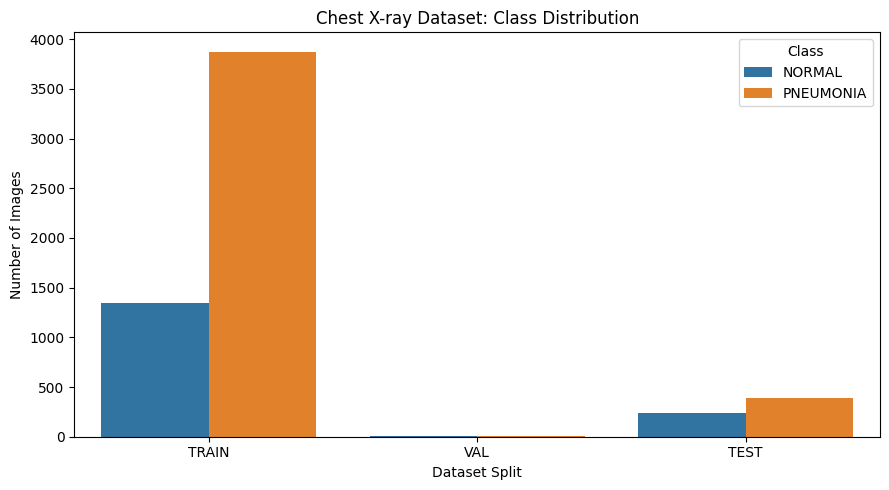

<Figure size 640x480 with 0 Axes>

In [88]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("data/interim/chest_xray")

records = []

for split in ["train", "val", "test"]:
    split_dir = DATA_DIR / split

    if not split_dir.exists():
        continue

    for class_dir in sorted(split_dir.iterdir()):
        if class_dir.is_dir():
            count = sum(
                1 for p in class_dir.iterdir()
                if p.is_file()
            )

            records.append({
                "Split": split.upper(),
                "Class": class_dir.name,
                "Count": count
            })

df_counts = pd.DataFrame(records)

display(df_counts)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=df_counts,
    x="Split",
    y="Count",
    hue="Class"
)
plt.title("Chest X-ray Dataset: Class Distribution")
plt.ylabel("Number of Images")
plt.xlabel("Dataset Split")
plt.tight_layout()
plt.show()

from pathlib import Path

FIGURE_DIR = Path("reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


plt.savefig(
    "reports/figures/class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)



plt.show()


## 3. Class Distribution Analysis

The dataset contains the following class distribution:

- **PNEUMONIA:** 4,273 images (72.97%)
- **NORMAL:** 1,583 images (27.03%)

The analysis shows that the dataset is imbalanced, with pneumonia images representing approximately 73% of all images. The number of pneumonia images is substantially higher than the number of normal images.

**Impact on model training:** A model trained on this dataset may become biased toward predicting the majority class. Therefore, accuracy alone may not provide a complete picture of model performance.

**Recommendation:** Evaluate the model using precision, recall, F1-score, a confusion matrix, and class-wise sensitivity. Class weighting or other imbalance-handling techniques can also be investigated if needed.

In [55]:

from pathlib import Path
import pandas as pd

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

records = []

for split in ["train", "val", "test"]:
    split_dir = DATA_DIR / split

    if not split_dir.exists():
        continue

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        for path in class_dir.rglob("*"):
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({
                    "filepath": str(path),
                    "filename": path.name,
                    "split": split,
                    "class_name": class_dir.name,
                    "extension": path.suffix.lower()
                })

df = pd.DataFrame(records)

print("Total images:", len(df))
print("Metadata shape:", df.shape)
display(df.head())


Total images: 5856
Metadata shape: (5856, 5)


,filepath,filename,split,class_name,extension
0,data/interim/chest_xray/train/NORMAL/NORMAL2-I...,NORMAL2-IM-1253-0001.jpeg,train,NORMAL,.jpeg
1,data/interim/chest_xray/train/NORMAL/NORMAL2-I...,NORMAL2-IM-1266-0001-0001.jpeg,train,NORMAL,.jpeg
2,data/interim/chest_xray/train/NORMAL/IM-0519-0...,IM-0519-0001-0001.jpeg,train,NORMAL,.jpeg
3,data/interim/chest_xray/train/NORMAL/NORMAL2-I...,NORMAL2-IM-0871-0001.jpeg,train,NORMAL,.jpeg
4,data/interim/chest_xray/train/NORMAL/IM-0482-0...,IM-0482-0001.jpeg,train,NORMAL,.jpeg


In [56]:

print("\nImages per class:")
print(df["class_name"].value_counts())

print("\nImages per split:")
print(df["split"].value_counts())

print("\nClass distribution by split:")
display(pd.crosstab(df["split"], df["class_name"]))



Images per class:
class_name
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64

Images per split:
split
train    5216
test      624
val        16
Name: count, dtype: int64

Class distribution by split:


class_name,NORMAL,PNEUMONIA
split,,
test,234,390
train,1341,3875
val,8,8


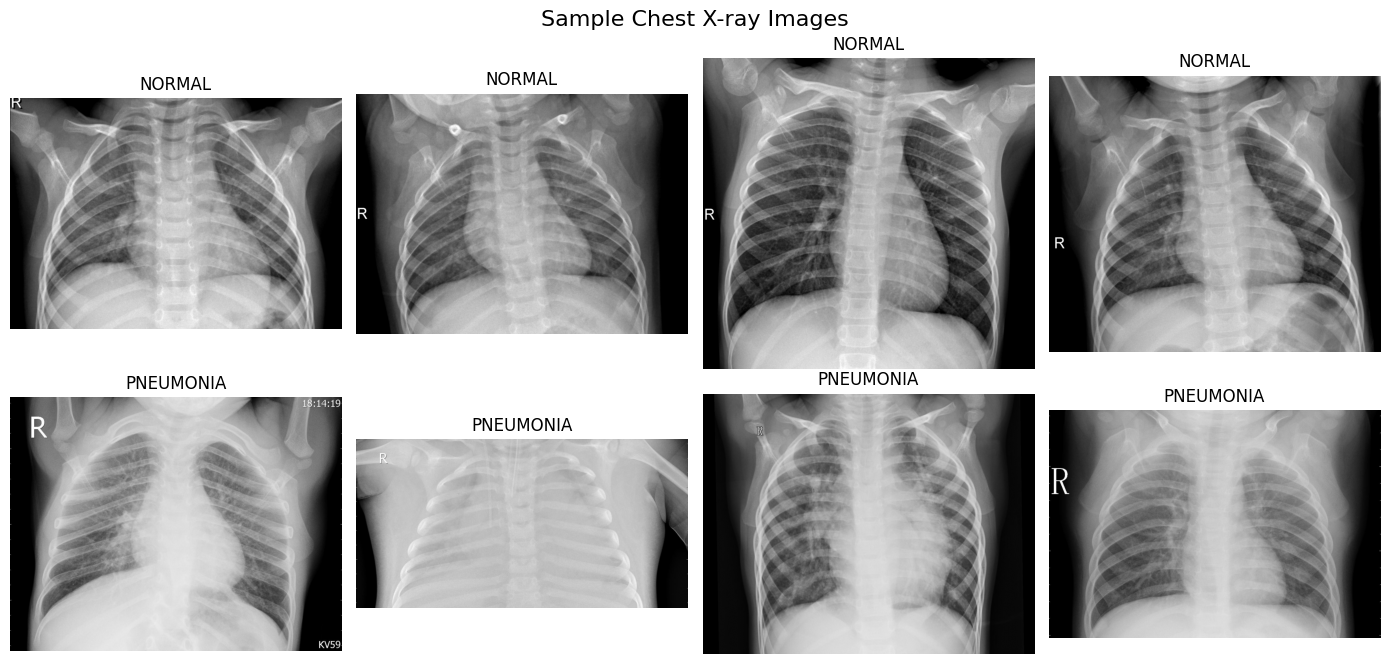

In [57]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random

DATA_DIR = Path("data/interim/chest_xray")
random.seed(42)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for row, class_name in enumerate(["NORMAL", "PNEUMONIA"]):
    image_dir = DATA_DIR / "train" / class_name

    image_paths = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    samples = random.sample(image_paths, min(4, len(image_paths)))

    for col, image_path in enumerate(samples):
        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("L"), cmap="gray")

        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.suptitle("Sample Chest X-ray Images", fontsize=16)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "sample_images.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()


## 4. Visual Inspection of Chest X-ray Images

Representative images from both the NORMAL and PNEUMONIA classes were visualized to understand the appearance of the input data.

Chest X-ray images contain anatomical structures such as the lungs, ribs, and surrounding tissues. Images in the pneumonia category may exhibit abnormal patterns or areas of increased opacity, while normal images may show fewer visible abnormalities.

However, visual appearances can overlap, and the differences are not always obvious. This makes automated classification a challenging task that requires careful preprocessing and model evaluation.

The sample images are displayed in grayscale to provide a consistent visual representation. These examples are useful for preliminary inspection but are not sufficient to establish a medical diagnosis.

Class Distribution Summary:


,Image Count,Percentage (%)
class_name,,
PNEUMONIA,4273,72.97
NORMAL,1583,27.03


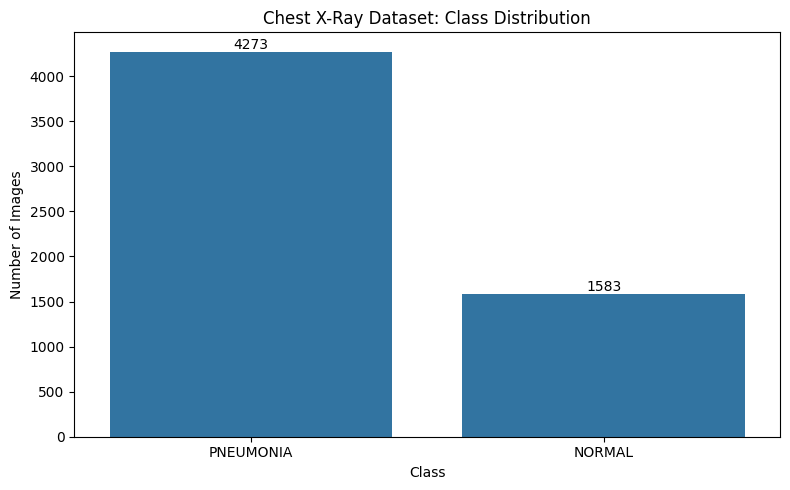

In [58]:

# EDA Step 3: Class Distribution

class_counts = df["class_name"].value_counts()
class_percentages = df["class_name"].value_counts(normalize=True) * 100

# Print actual counts and percentages
summary = pd.DataFrame({
    "Image Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

print("Class Distribution Summary:")
display(summary)

# Create bar chart
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

# Display count above each bar
for i, count in enumerate(class_counts.values):
    ax.text(i, count + 30, str(count), ha="center")

plt.title("Chest X-Ray Dataset: Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()


In [59]:
print("Metadata rows:", len(df))
print("\nClass counts:")
print(df["class_name"].value_counts())

print("\nCounts by split and class:")
display(pd.crosstab(df["split"], df["class_name"], margins=True))

Metadata rows: 5856

Class counts:
class_name
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64

Counts by split and class:


class_name,NORMAL,PNEUMONIA,All
split,,,
test,234,390,624
train,1341,3875,5216
val,8,8,16
All,1583,4273,5856


Class counts across dataset splits:


class_name,NORMAL,PNEUMONIA
split,,
test,234,390
train,1341,3875
val,8,8


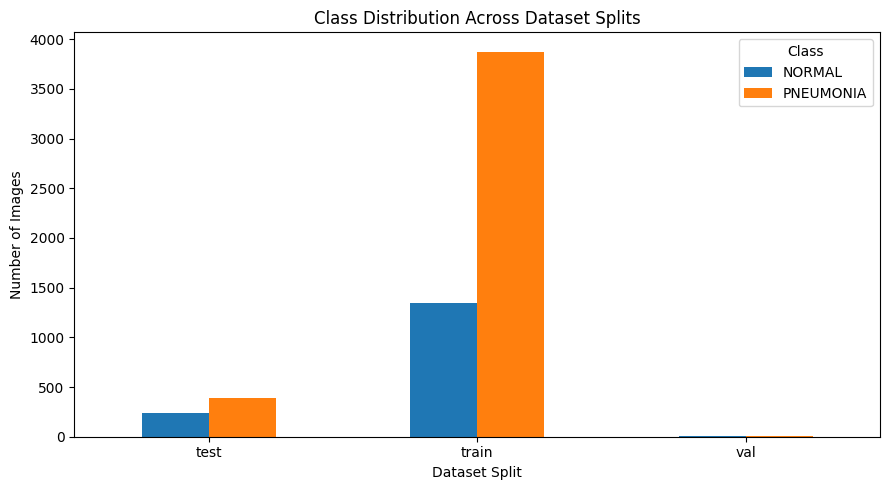

Class percentages within each split:


class_name,NORMAL,PNEUMONIA
split,,
test,37.50,62.50
train,25.71,74.29
val,50.00,50.00


In [60]:

# EDA Step 4: Compare Dataset Splits

split_counts = pd.crosstab(
    df["split"],
    df["class_name"]
)

print("Class counts across dataset splits:")
display(split_counts)

# Plot class counts
ax = split_counts.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.legend(title="Class")
plt.tight_layout()


plt.savefig(
    FIGURE_DIR / "split_distribution.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

# Calculate class percentages within each split
print("Class percentages within each split:")
display(
    (split_counts.div(split_counts.sum(axis=1), axis=0) * 100).round(2)
)


## 5. Training, Validation, and Testing Split Analysis

The distribution of classes was examined separately for each dataset split.

| Dataset split | NORMAL | PNEUMONIA | Total |
|---|---:|---:|---:|
| Training | 1,341 | 3,875 | 5,216 |
| Validation | 8 | 8 | 16 |
| Testing | 234 | 390 | 624 |

The training set contains approximately 74.29% pneumonia images and 25.71% normal images. The testing set contains 62.50% pneumonia images and 37.50% normal images. The validation set has equal numbers of images from both classes, but its small size limits the reliability of performance estimates.

**Observation:** The class proportions differ between the training and testing sets. This difference should be considered when interpreting the final evaluation metrics. The split comparison alone does not establish whether images from the same patient occur across multiple subsets.

In [61]:

# EDA Step 5: Analyze Original Image Dimensions

from pathlib import Path
from PIL import Image, UnidentifiedImageError
import pandas as pd

metadata = []

for _, row in df.iterrows():
    try:
        with Image.open(row["filepath"]) as img:
            metadata.append({
                **row.to_dict(),
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "file_size_kb": round(
                    Path(row["filepath"]).stat().st_size / 1024, 2
                ),
                "valid_image": True
            })

    except (UnidentifiedImageError, OSError, ValueError):
        metadata.append({
            **row.to_dict(),
            "width": None,
            "height": None,
            "mode": None,
            "file_size_kb": None,
            "valid_image": False
        })

metadata_df = pd.DataFrame(metadata)

print("Total image records:", len(metadata_df))
print("\nImage dimension and file size statistics:")

display(
    metadata_df[
        ["width", "height", "file_size_kb"]
    ].describe()
)

print("\nImage color modes:")
print(metadata_df["mode"].value_counts(dropna=False))

print("\nImage validity:")
print(metadata_df["valid_image"].value_counts(dropna=False))


Total image records: 5856

Image dimension and file size statistics:


,width,height,file_size_kb
count,5856.000000,5856.000000,5856.000000
mean,1327.880806,970.689037,206.199255
std,363.500922,383.392117,258.600342
min,384.000000,127.000000,5.310000
25%,1056.000000,688.000000,54.750000
50%,1281.000000,888.000000,93.590000
75%,1560.000000,1187.000000,230.487500
max,2916.000000,2713.000000,2357.760000



Image color modes:
mode
L      5573
RGB     283
Name: count, dtype: int64

Image validity:
valid_image
True    5856
Name: count, dtype: int64


## 6. Image Dimension and File Size Analysis

The original image dimensions and file sizes were examined to understand the variability of the dataset.

The analysis found the following:

- Mean image width: approximately 1,328 pixels
- Mean image height: approximately 971 pixels
- Median image width: 1,281 pixels
- Median image height: 888 pixels
- Median file size: approximately 93.59 KB
- Maximum file size: approximately 2,357.76 KB

The images have different widths and heights, indicating that the dataset does not use a single standardized resolution. This variation can increase computational requirements and complicate batch processing during model training.

**Preprocessing implication:** Images can be resized to a fixed input resolution, such as 150 × 150 pixels, if that is the input size selected for the model. The same preprocessing procedure must be applied consistently to training, validation, and testing images. Resizing may remove some fine details, so its effect on model performance should be evaluated.

In [62]:

metadata_df.to_csv("image_metadata.csv", index=False)

print("Saved image_metadata.csv")
print("Rows:", len(metadata_df))
print("Columns:", len(metadata_df.columns))


Saved image_metadata.csv
Rows: 5856
Columns: 10


## 7. Image Quality and Color Mode Analysis

The image inspection identified the following color modes:

- **Grayscale (L):** 5,573 images
- **RGB:** 283 images

All **5,856 images** were successfully opened using the image-processing library, and no invalid images were detected by this check.

Most images are grayscale, which is expected for chest X-ray data. However, a small number of images use RGB mode. To ensure consistent model input, images should be converted to a common format, such as grayscale or three-channel RGB, depending on the model architecture and preprocessing pipeline.

**Observation:** No unreadable images were detected by the implemented check. This confirms that the images could be opened successfully, but it does not guarantee that every image is clinically useful or free from other data-quality issues.

In [63]:
from google.colab import files
files.download("image_metadata.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [64]:

print("Most common original image dimensions:")

display(
    metadata_df[metadata_df["valid_image"]]
    .groupby(["width", "height"])
    .size()
    .reset_index(name="image_count")
    .sort_values("image_count", ascending=False)
    .head(10)
)

plt.savefig(
    FIGURE_DIR / "image_dimensions.png",
    dpi=300,
    bbox_inches="tight"
)



Most common original image dimensions:


,width,height,image_count
841,1008,704,7
1112,1072,648,7
1157,1080,728,6
752,992,608,6
750,992,592,6
1755,1216,872,6
800,1000,704,5
838,1008,680,5
1496,1160,736,5
1603,1184,792,5


<Figure size 640x480 with 0 Axes>

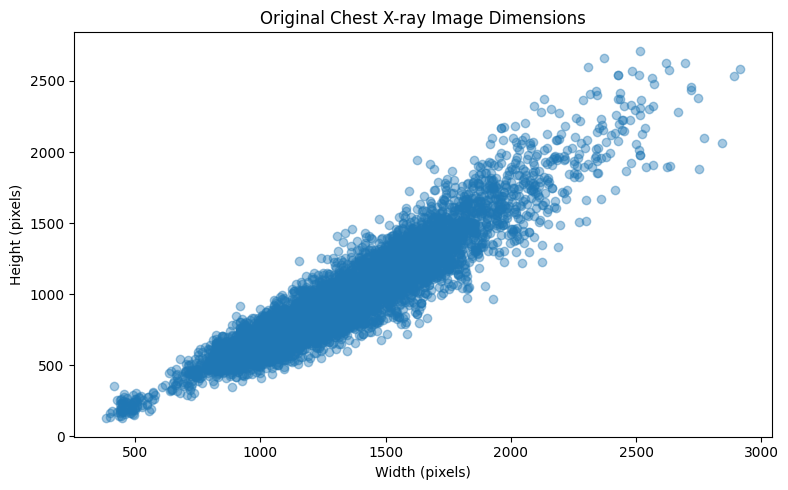

In [65]:

plt.figure(figsize=(8, 5))

plt.scatter(
    metadata_df["width"],
    metadata_df["height"],
    alpha=0.4
)

plt.title("Original Chest X-ray Image Dimensions")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "image_dimensions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## Step 6: Pixel Intensity Analysis

This section analyzes the grayscale pixel intensity distribution of the chest X-ray images. The objective is to understand brightness and contrast variations in the dataset and identify potential differences between the NORMAL and PNEUMONIA classes.

Grayscale pixel values range from 0 (black) to 255 (white). Intermediate values represent different shades of gray. The analysis uses a reproducible sample of up to 500 images to reduce computation time.

The results provide descriptive information about the image dataset and help inform preprocessing decisions. Pixel intensity alone cannot be used to diagnose pneumonia.

In [66]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Reproducible sample of up to 500 images
sample_df = df.sample(
    n=min(500, len(df)),
    random_state=42
)

pixel_values = []

for _, row in sample_df.iterrows():
    try:
        with Image.open(row["filepath"]) as img:
            img = img.convert("L")
            img = img.resize((128, 128))

            pixels = np.asarray(img, dtype=np.uint8)
            pixel_values.extend(pixels.ravel())

    except (OSError, ValueError):
        continue

pixel_values = np.asarray(pixel_values, dtype=np.uint8)

print("Number of sampled images:", len(sample_df))
print("Number of sampled pixels:", len(pixel_values))

if len(pixel_values) > 0:
    print("Mean intensity:", round(float(np.mean(pixel_values)), 2))
    print("Standard deviation:", round(float(np.std(pixel_values)), 2))
    print("Minimum intensity:", int(np.min(pixel_values)))
    print("Maximum intensity:", int(np.max(pixel_values)))
else:
    print("No valid pixels were collected.")


Number of sampled images: 500
Number of sampled pixels: 8192000
Mean intensity: 123.32
Standard deviation: 60.14
Minimum intensity: 0
Maximum intensity: 255


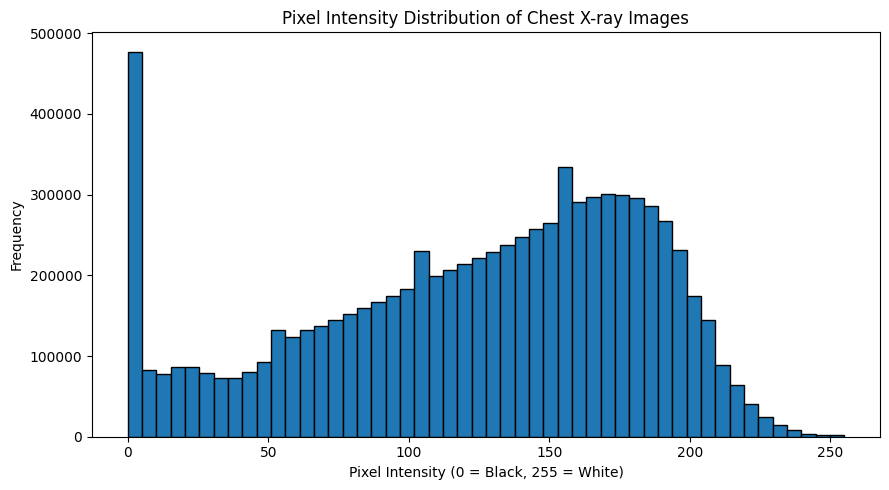

In [67]:

if len(pixel_values) > 0:
    plt.figure(figsize=(9, 5))

    plt.hist(
        pixel_values,
        bins=50,
        edgecolor="black"
    )

    plt.title("Pixel Intensity Distribution of Chest X-ray Images")
    plt.xlabel("Pixel Intensity (0 = Black, 255 = White)")
    plt.ylabel("Frequency")
    plt.tight_layout()

    plt.savefig(
        "pixel_intensity_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
else:
    print("Cannot plot the distribution because no valid pixels were collected.")


### Pixel Intensity Analysis — Interpretation

The histogram shows the distribution of grayscale pixel values across the sampled chest X-ray images. The mean intensity provides a measure of average brightness, while the standard deviation indicates the overall variation in pixel values.

A distribution concentrated toward lower values suggests that darker pixels are frequent. A broader distribution indicates greater variation in brightness and contrast.

These results describe the sampled images collectively. They do not establish whether an individual image is normal or contains pneumonia. Further analysis would be required to compare intensity distributions between classes.

Step 7: Brightness Comparison Between Classes

In [68]:

image_stats = []

for _, row in df.iterrows():
    try:
        with Image.open(row["filepath"]) as img:
            pixels = np.asarray(
                img.convert("L").resize((128, 128)),
                dtype=np.float32
            )

            image_stats.append({
                "filepath": row["filepath"],
                "split": row["split"],
                "class_name": row["class_name"],
                "mean_intensity": float(pixels.mean()),
                "std_intensity": float(pixels.std())
            })

    except (OSError, ValueError):
        continue

intensity_df = pd.DataFrame(image_stats)

print("Images analyzed:", len(intensity_df))

display(
    intensity_df.groupby("class_name")[
        ["mean_intensity", "std_intensity"]
    ].agg(["mean", "median", "std"]).round(2)
)


Images analyzed: 5856


mean_intensity                std_intensity             
                     mean  median    std          mean median   std
class_name                                                         
NORMAL             122.65  122.39  13.54         60.77  61.00  5.82
PNEUMONIA          122.84  122.87  19.89         54.99  54.37  9.91

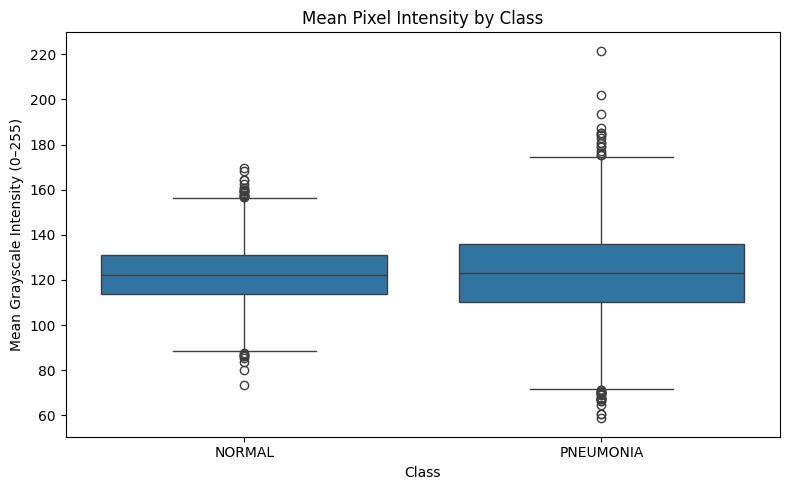

In [69]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=intensity_df,
    x="class_name",
    y="mean_intensity"
)

plt.title("Mean Pixel Intensity by Class")
plt.xlabel("Class")
plt.ylabel("Mean Grayscale Intensity (0–255)")
plt.tight_layout()
plt.savefig(
    "mean_intensity_by_class.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Brightness Comparison — Interpretation

The mean grayscale intensity and standard deviation were calculated for each image and summarized separately for the NORMAL and PNEUMONIA classes.

The box plot compares the distributions of average image brightness. Differences between the classes, if observed, may reflect image acquisition conditions, exposure, contrast, or image characteristics.

These measurements are descriptive and do not establish that brightness can reliably distinguish NORMAL from PNEUMONIA images. The actual class statistics and the degree of overlap between the box plots should be considered when interpreting the results.

Step 8: Image Aspect Ratio Analysis

In [70]:

# Use images with valid, positive dimensions
valid_metadata = metadata_df[
    metadata_df["valid_image"]
    & metadata_df["width"].notna()
    & metadata_df["height"].notna()
    & (metadata_df["height"] > 0)
].copy()

valid_metadata["aspect_ratio"] = (
    valid_metadata["width"] / valid_metadata["height"]
)

print("Images analyzed:", len(valid_metadata))
print("\nAspect ratio statistics:")
display(valid_metadata["aspect_ratio"].describe().round(3))


Images analyzed: 5856

Aspect ratio statistics:


,aspect_ratio
count,5856.000
mean,1.443
std,0.254
min,0.835
25%,1.262
50%,1.416
75%,1.586
max,3.379


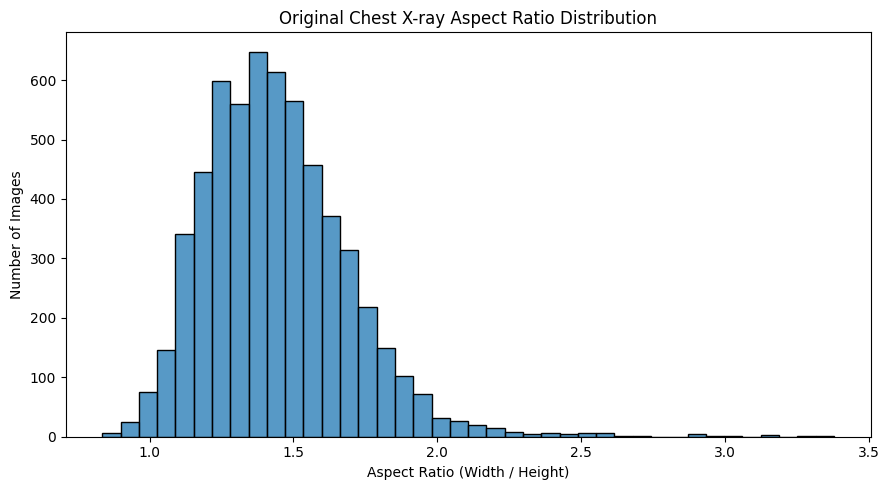

In [71]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=valid_metadata,
    x="aspect_ratio",
    bins=40
)

plt.title("Original Chest X-ray Aspect Ratio Distribution")
plt.xlabel("Aspect Ratio (Width / Height)")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.savefig(
    "aspect_ratio_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Aspect Ratio Analysis — Interpretation

The aspect ratio was calculated by dividing each image's original width by its height. This analysis helps identify variation in the shape of the chest X-ray images.

An aspect ratio close to 1 indicates a nearly square image, while a value greater than 1 indicates a wider-than-tall image. A value below 1 indicates a taller-than-wide image.

If images with different aspect ratios are directly resized to 150 × 150 pixels, their proportions may change, potentially distorting anatomical structures. The findings should therefore be shared with the modeling team when selecting the preprocessing strategy.

Possible alternatives include preserving the aspect ratio through padding or using another input size appropriate for the model. The final approach should be evaluated consistently across all dataset splits.

**Step 9: Exact Duplicate Image Detection.**

In [72]:

import hashlib

def calculate_sha256(filepath):
    sha = hashlib.sha256()

    with open(filepath, "rb") as file:
        for chunk in iter(lambda: file.read(8192), b""):
            sha.update(chunk)

    return sha.hexdigest()

metadata_df["sha256"] = metadata_df["filepath"].apply(
    calculate_sha256
)

print("Hash calculation completed.")
print("Images hashed:", len(metadata_df))


Hash calculation completed.
Images hashed: 5856


In [73]:

duplicates = metadata_df[
    metadata_df.duplicated(
        subset="sha256",
        keep=False
    )
].sort_values("sha256")

print("Files involved in exact duplicates:", len(duplicates))

display(
    duplicates[
        ["filename", "split", "class_name", "filepath", "sha256"]
    ].head(20)
)


Files involved in exact duplicates: 62


,filename,split,class_name,filepath,sha256
3639,person1159_virus_1945.jpeg,train,PNEUMONIA,data/interim/chest_xray/train/PNEUMONIA/person...,0033d6b3f444134e4d3a320b4c9e34cdbc4ffe1fdb9002...
1517,person1159_virus_1944.jpeg,train,PNEUMONIA,data/interim/chest_xray/train/PNEUMONIA/person...,0033d6b3f444134e4d3a320b4c9e34cdbc4ffe1fdb9002...
5183,person124_virus_246.jpeg,train,PNEUMONIA,data/interim/chest_xray/train/PNEUMONIA/person...,1679da3844455b96ea5e792b12d24a832c4dba570628c2...
4497,person124_virus_247.jpeg,train,PNEUMONIA,data/interim/chest_xray/train/PNEUMONIA/person...,1679da3844455b96ea5e792b12d24a832c4dba570628c2...
2129,person1261_virus_2147.jpeg,train,PNEUMONIA,data/interim/chest_xray/train/PNEUMONIA/person...,1e273d0058cfb3cf5fb401b74797903a3e66c75fd2dbd8...
4208,person1261_virus_2148.jpeg,train,PNEUMONIA,data/interim/chest_xray/train/PNEUMONIA/person...,1e273d0058cfb3cf5fb401b74797903a3e66c75fd2dbd8...
218,NORMAL2-IM-0587-0001-0001.jpeg,train,NORMAL,data/interim/chest_xray/train/NORMAL/NORMAL2-I...,3853a4552e0bc9aea1f45b2e7ee27be5954cdf9a0365d7...
498,NORMAL2-IM-0587-0001-0002.jpeg,train,NORMAL,data/interim/chest_xray/train/NORMAL/NORMAL2-I...,3853a4552e0bc9aea1f45b2e7ee27be5954cdf9a0365d7...
5240,NORMAL2-IM-0173-0001-0002.jpeg,test,NORMAL,data/interim/chest_xray/test/NORMAL/NORMAL2-IM...,409f0f6c0f8a5b8ed4e0645633b07812aff5991aaee75b...
5301,NORMAL2-IM-0173-0001-0001.jpeg,test,NORMAL,data/interim/chest_xray/test/NORMAL/NORMAL2-IM...,409f0f6c0f8a5b8ed4e0645633b07812aff5991aaee75b...


In [74]:

hash_split_counts = (
    metadata_df.groupby("sha256")["split"].nunique()
)

cross_split_hashes = hash_split_counts[
    hash_split_counts > 1
]

print(
    "Exact duplicate groups spanning multiple splits:",
    len(cross_split_hashes)
)

if len(cross_split_hashes) > 0:
    cross_split_details = metadata_df[
        metadata_df["sha256"].isin(cross_split_hashes.index)
    ].sort_values(["sha256", "split"])

    display(
        cross_split_details[
            ["filename", "split", "class_name", "filepath", "sha256"]
        ]
    )
else:
    print("No cross-split exact duplicate groups were found.")


Exact duplicate groups spanning multiple splits: 0
No cross-split exact duplicate groups were found.


### Duplicate Detection — Interpretation

SHA-256 hashes were calculated for the image files to identify files with identical byte content. Files sharing the same hash are treated as exact duplicates for this analysis.

The duplicate check also examines whether an identical file occurs in more than one dataset split. Cross-split duplicates can lead to data leakage and overly optimistic evaluation results if the same image is used during training and testing.

Any identified duplicate groups should be inspected and reported to the project team before making changes to the dataset. No files should be deleted or moved automatically.

This method does not detect visually similar images that differ in compression, resolution, cropping, or pixel content. It also does not establish whether two different images belong to the same patient.

In [75]:

from pathlib import Path
import shutil

OUTPUT_DIR = Path("reports/figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save image metadata, including dimensions and hashes
metadata_df.to_csv(
    "image_metadata.csv",
    index=False
)

# Save per-image brightness statistics
intensity_df.to_csv(
    "pixel_intensity_summary.csv",
    index=False
)

# Save aspect ratio statistics for valid images
valid_metadata.to_csv(
    "image_aspect_ratio_summary.csv",
    index=False
)

# Move existing figures into the report directory
figure_names = [
    "pixel_intensity_distribution.png",
    "mean_intensity_by_class.png",
    "aspect_ratio_distribution.png"
]

for name in figure_names:
    source = Path(name)

    if source.exists():
        shutil.copy2(source, OUTPUT_DIR / name)
        print("Saved figure:", OUTPUT_DIR / name)
    else:
        print("Figure not found yet:", name)

print("\nMetadata and analysis results saved.")
print("Figure directory:", OUTPUT_DIR.resolve())


Saved figure: reports/figures/pixel_intensity_distribution.png
Saved figure: reports/figures/mean_intensity_by_class.png
Saved figure: reports/figures/aspect_ratio_distribution.png

Metadata and analysis results saved.
Figure directory: /content/reports/figures


## Step 11: Image Quality Analysis

This section evaluates the visual characteristics of chest X-ray images using brightness, contrast, and a basic sharpness indicator. The objective is to identify potentially unusual images for further inspection before CNN training.

Brightness is measured using the mean grayscale pixel intensity, contrast is approximated using the standard deviation of pixel intensities, and sharpness is estimated using the variance of the Laplacian.

These measurements are preliminary image-quality indicators. They do not establish medical validity or determine whether an image is correctly labeled.

In [76]:

%pip install -q opencv-python-headless


In [77]:

import cv2
import numpy as np
import pandas as pd
from PIL import Image

quality_records = []

for _, row in df.iterrows():
    try:
        with Image.open(row["filepath"]) as img:
            gray = np.asarray(
                img.convert("L").resize((128, 128)),
                dtype=np.uint8
            )

        brightness = float(gray.mean())
        contrast = float(gray.std())

        sharpness = float(
            cv2.Laplacian(gray, cv2.CV_64F).var()
        )

        quality_records.append({
            "filepath": row["filepath"],
            "split": row["split"],
            "class_name": row["class_name"],
            "brightness": brightness,
            "contrast": contrast,
            "sharpness": sharpness
        })

    except (OSError, ValueError) as error:
        print(f"Skipped {row['filepath']}: {error}")

quality_df = pd.DataFrame(quality_records)

print("Images analyzed:", len(quality_df))
display(
    quality_df.groupby("class_name")[
        ["brightness", "contrast", "sharpness"]
    ].agg(["mean", "median", "std"]).round(2)
)


Images analyzed: 5856


brightness                contrast              sharpness          \
                 mean  median    std     mean median   std      mean  median   
class_name                                                                     
NORMAL         122.65  122.39  13.54    60.77  61.00  5.82    517.60  484.12   
PNEUMONIA      122.84  122.87  19.89    54.99  54.37  9.91    335.13  300.13   

                    
               std  
class_name          
NORMAL      174.41  
PNEUMONIA   161.27

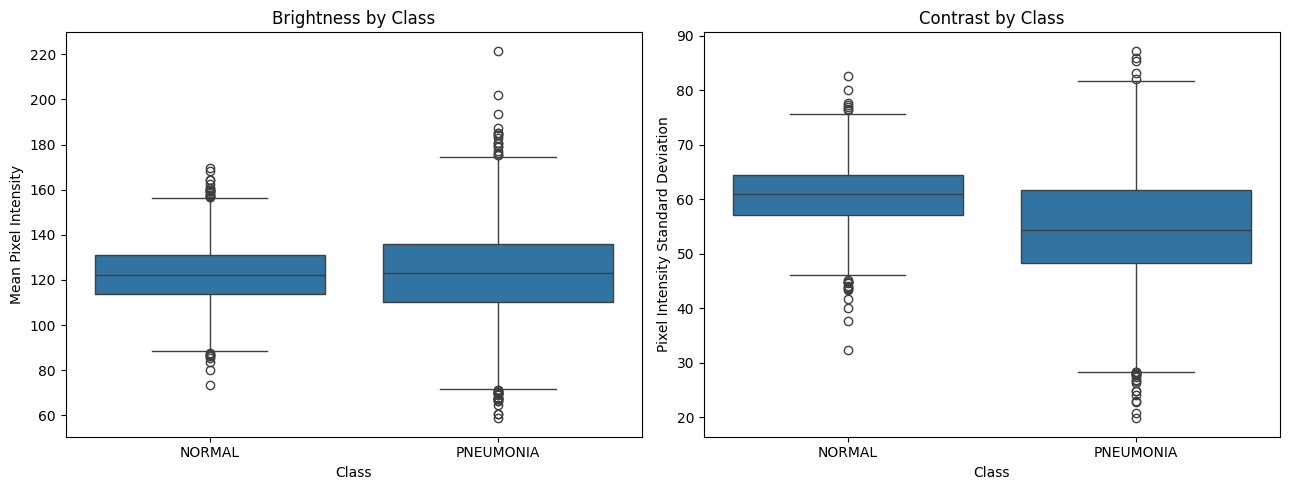

In [78]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=quality_df,
    x="class_name",
    y="brightness",
    ax=axes[0]
)
axes[0].set_title("Brightness by Class")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Mean Pixel Intensity")

sns.boxplot(
    data=quality_df,
    x="class_name",
    y="contrast",
    ax=axes[1]
)
axes[1].set_title("Contrast by Class")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Pixel Intensity Standard Deviation")

plt.tight_layout()
plt.savefig(
    "image_quality_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Image Quality Analysis — Interpretation

Brightness represents the average grayscale intensity of an image. Contrast indicates the variation in pixel intensities, while sharpness is approximated using the variance of the Laplacian.

The class-wise summary and box plots help identify differences in these characteristics and potentially unusual images that may require inspection.

A high sharpness score does not necessarily indicate a better medical image because noise and image content can also affect the score. No images should be automatically removed based on arbitrary thresholds.

The observed statistics should be recorded after execution and reviewed alongside the original images.

In [79]:

total_images = len(df)

class_counts = df["class_name"].value_counts()
class_percentages = df["class_name"].value_counts(normalize=True) * 100
split_counts = df["split"].value_counts()

valid_images = int(metadata_df["valid_image"].fillna(False).sum())
invalid_images = int(
    (~metadata_df["valid_image"].fillna(False)).sum()
)

summary_rows = [
    ("Total images", total_images),
    ("NORMAL images", int(class_counts.get("NORMAL", 0))),
    ("PNEUMONIA images", int(class_counts.get("PNEUMONIA", 0))),
    ("NORMAL percentage", round(class_percentages.get("NORMAL", 0), 2)),
    ("PNEUMONIA percentage", round(class_percentages.get("PNEUMONIA", 0), 2)),
    ("Training images", int(split_counts.get("train", 0))),
    ("Validation images", int(split_counts.get("val", 0))),
    ("Testing images", int(split_counts.get("test", 0))),
    ("Valid images", valid_images),
    ("Invalid images", invalid_images),
    ("Mean width", round(metadata_df["width"].mean(), 2)),
    ("Mean height", round(metadata_df["height"].mean(), 2)),
]

eda_summary = pd.DataFrame(
    summary_rows,
    columns=["Metric", "Value"]
)

display(eda_summary)

eda_summary.to_csv("eda_summary.csv", index=False)
print("Saved eda_summary.csv")


,Metric,Value
0,Total images,5856.00
1,NORMAL images,1583.00
2,PNEUMONIA images,4273.00
3,NORMAL percentage,27.03
4,PNEUMONIA percentage,72.97
5,Training images,5216.00
6,Validation images,16.00
7,Testing images,624.00
8,Valid images,5856.00
9,Invalid images,0.00


Saved eda_summary.csv


In [80]:

from pathlib import Path

FIGURE_DIR = Path("reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Figures will be saved to:", FIGURE_DIR.resolve())


Figures will be saved to: /content/reports/figures


# Final EDA Findings

## 1. Dataset Composition

The dataset contains 5,856 chest X-ray images: 5,216 training images, 16 validation images, and 624 testing images.

## 2. Class Distribution

PNEUMONIA represents 72.97% of the dataset, while NORMAL represents 27.03%. This class imbalance should be considered when training and evaluating the classification model.

## 3. Image Dimensions and Color Modes

The original image dimensions vary considerably. The mean width is approximately 1,327.88 pixels and the mean height is approximately 970.69 pixels. Most images are grayscale, while a smaller proportion use RGB color mode.

## 4. Image Quality

Brightness, contrast, and sharpness indicators are calculated to support preliminary quality assessment. Potentially unusual images should be inspected rather than automatically discarded.

## 5. Data Integrity and Duplicates

The initial integrity check found that all 5,856 images could be opened successfully. Exact duplicate detection should be used to investigate redundant files and possible overlap between dataset splits.

## 6. Validation Limitations

The validation set contains only 16 images, with eight images per class. This is too small for a stable estimate of model performance. The project team should review the validation strategy and check patient-level separation where patient identifiers are available.

## 7. Recommendations

- Apply consistent image resizing, channel handling, and normalization.
- Consider class imbalance when selecting training strategies and evaluation metrics.
- Review exact duplicates and possible cross-split overlap.
- Consider preserving image proportions when selecting the resizing strategy.
- Evaluate classification performance using precision, recall, F1-score, and a confusion matrix.
- Record actual image-quality and aspect-ratio statistics before finalizing the report.

## 8. Conclusion

This EDA establishes the initial characteristics of the chest X-ray dataset and provides information to guide preprocessing and model development. Further image-quality and duplicate checks should be interpreted using their actual outputs before the dataset is finalized for CNN training.

In [81]:

from pathlib import Path
import pandas as pd

REPORT_DIR = Path("reports")
FIGURE_DIR = REPORT_DIR / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Dataset composition
class_counts = df["class_name"].value_counts()
split_counts = df["split"].value_counts()

# Image integrity
valid_flags = metadata_df["valid_image"].fillna(False).astype(bool)

summary = pd.DataFrame([
    {"Metric": "Total images", "Value": len(df)},
    {"Metric": "NORMAL images", "Value": int(class_counts.get("NORMAL", 0))},
    {"Metric": "PNEUMONIA images", "Value": int(class_counts.get("PNEUMONIA", 0))},
    {"Metric": "NORMAL percentage", "Value": round(class_counts.get("NORMAL", 0) / len(df) * 100, 2)},
    {"Metric": "PNEUMONIA percentage", "Value": round(class_counts.get("PNEUMONIA", 0) / len(df) * 100, 2)},
    {"Metric": "Training images", "Value": int(split_counts.get("train", 0))},
    {"Metric": "Validation images", "Value": int(split_counts.get("val", 0))},
    {"Metric": "Testing images", "Value": int(split_counts.get("test", 0))},
    {"Metric": "Readable images", "Value": int(valid_flags.sum())},
    {"Metric": "Unreadable images", "Value": int((~valid_flags).sum())},
])

summary.to_csv(REPORT_DIR / "EDA_Summary.csv", index=False)

display(summary)
print("Saved:", REPORT_DIR / "EDA_Summary.csv")


,Metric,Value
0,Total images,5856.00
1,NORMAL images,1583.00
2,PNEUMONIA images,4273.00
3,NORMAL percentage,27.03
4,PNEUMONIA percentage,72.97
5,Training images,5216.00
6,Validation images,16.00
7,Testing images,624.00
8,Readable images,5856.00
9,Unreadable images,0.00


Saved: reports/EDA_Summary.csv


In [82]:

# Save the complete image metadata
metadata_df.to_csv(
    REPORT_DIR / "image_metadata.csv",
    index=False
)

# Export tables only when the corresponding analysis exists
analysis_tables = {
    "intensity_df": "pixel_intensity_summary.csv",
    "quality_df": "image_quality_summary.csv",
    "valid_metadata": "image_aspect_ratio_summary.csv",
}

for variable_name, filename in analysis_tables.items():
    if variable_name in globals():
        table = globals()[variable_name]
        table.to_csv(REPORT_DIR / filename, index=False)
        print("Saved:", REPORT_DIR / filename)
    else:
        print("Not generated yet:", variable_name)

print("Saved:", REPORT_DIR / "image_metadata.csv")


Saved: reports/pixel_intensity_summary.csv
Saved: reports/image_quality_summary.csv
Saved: reports/image_aspect_ratio_summary.csv
Saved: reports/image_metadata.csv


In [83]:

import shutil

figure_names = [
    "class_distribution.png",
    "split_distribution.png",
    "sample_images.png",
    "image_dimensions.png",
    "pixel_intensity_distribution.png",
    "mean_intensity_by_class.png",
    "aspect_ratio_distribution.png",
    "image_quality_comparison.png",
]

for name in figure_names:
    source = Path(name)

    if source.exists():
        destination = FIGURE_DIR / name
        shutil.copy2(source, destination)
        print("Copied:", destination)
    else:
        print("Not found; skipping:", name)

print("\nFigures currently saved:")
for path in sorted(FIGURE_DIR.glob("*.png")):
    print("-", path.name)


Not found; skipping: class_distribution.png
Not found; skipping: split_distribution.png
Not found; skipping: sample_images.png
Not found; skipping: image_dimensions.png
Copied: reports/figures/pixel_intensity_distribution.png
Copied: reports/figures/mean_intensity_by_class.png
Copied: reports/figures/aspect_ratio_distribution.png
Copied: reports/figures/image_quality_comparison.png

Figures currently saved:
- aspect_ratio_distribution.png
- class_distribution.png
- image_dimensions.png
- image_quality_comparison.png
- mean_intensity_by_class.png
- pixel_intensity_distribution.png
- sample_images.png
- split_distribution.png
- your_chart_name.png


In [89]:

from pathlib import Path
import zipfile

report_dir = Path("reports")
figures_dir = report_dir / "figures"

# Remove only the known blank placeholder figure
placeholder = figures_dir / "your_chart_name.png"
if placeholder.exists():
    placeholder.unlink()

# Rebuild the archive from the corrected report directory
zip_path = Path("EDA_deliverables.zip")

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:
    for path in sorted(report_dir.rglob("*")):
        if path.is_file():
            archive.write(path, path.as_posix())

# Verify archive integrity and required figures
required_figures = [
    "class_distribution.png",
    "split_distribution.png",
    "sample_images.png",
    "image_dimensions.png",
    "pixel_intensity_distribution.png",
    "mean_intensity_by_class.png",
    "aspect_ratio_distribution.png",
    "image_quality_comparison.png",
]

with zipfile.ZipFile(zip_path, "r") as archive:
    names = set(archive.namelist())
    print("ZIP integrity:", archive.testzip())

    for filename in required_figures:
        member = f"reports/figures/{filename}"
        print(
            "PASS" if member in names else "MISSING",
            filename
        )

    print(
        "Placeholder removed:",
        "reports/figures/your_chart_name.png" not in names
    )


ZIP integrity: None
PASS class_distribution.png
PASS split_distribution.png
PASS sample_images.png
PASS image_dimensions.png
PASS pixel_intensity_distribution.png
PASS mean_intensity_by_class.png
PASS aspect_ratio_distribution.png
PASS image_quality_comparison.png
Placeholder removed: True


In [84]:

from pathlib import Path

REPORT_DIR = Path("reports")
FIGURE_DIR = REPORT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

report_text = """
# Exploratory Data Analysis Report
## Chest X-ray Classification — Group 1

## 1. Introduction and Objectives

This report documents exploratory data analysis of chest X-ray
images belonging to the NORMAL and PNEUMONIA classes. The objective
is to examine dataset composition, image characteristics, and
data integrity before model development.

## 2. Dataset Source and Structure

Dataset: Chest X-Ray Images (Pneumonia)
Source: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia

The dataset contains training, validation, and testing subsets.

## 3. Dataset Size and Class Distribution

The dataset contains 5,856 images:
- NORMAL: 1,583 (27.03%)
- PNEUMONIA: 4,273 (72.97%)

The class distribution is imbalanced and should be considered
when training and evaluating the classifier.

## 4. Dataset Split Analysis

- Training: 5,216 images
- Validation: 16 images
- Testing: 624 images

The validation set contains only eight images per class.
This is too small for a stable estimate of model performance.
The project team should review the validation strategy.

## 5. Sample Image Visualization

Representative images from both classes were inspected.
Visual examples illustrate the input data but do not establish
a medical diagnosis.

Figure: figures/sample_images.png

## 6. Image Dimensions and Color Modes

The mean image width is approximately 1,327.88 pixels, and
the mean height is approximately 970.69 pixels.

Color modes:
- Grayscale: 5,573 images
- RGB: 283 images

The variation in dimensions supports using a consistent
preprocessing pipeline. Resizing should be assessed carefully
because changing image proportions can distort anatomy.

Figure: figures/image_dimensions.png

## 7. Pixel Intensity and Aspect Ratio Analysis

The aspect-ratio results are:
- Mean: 1.443
- Median: 1.416
- Minimum: 0.835
- Maximum: 3.379

These results show variation in the original image proportions.
The preprocessing strategy should consider preserving the
aspect ratio where appropriate.

Overall pixel intensity analysis is descriptive and should not
be interpreted as a diagnostic test.

Figure: figures/pixel_intensity_distribution.png

## 8. Image Quality Analysis

The following class-wise results were obtained:

| Measurement | NORMAL mean | PNEUMONIA mean |
|---|---:|---:|
| Brightness | 122.65 | 122.84 |
| Contrast (standard deviation) | 60.77 | 54.99 |
| Sharpness (Laplacian variance) | 517.60 | 335.13 |

Average brightness is similar between the two classes in these
results. The average contrast and sharpness indicators differ.

These measurements are descriptive. Laplacian variance can be
affected by image content and noise and does not independently
establish medical image quality.

Figure: figures/image_quality_comparison.png

## 9. Duplicate Image Analysis

The exact-duplicate analysis identified 62 files involved in
duplicate groups. Zero exact duplicate groups were found to
span multiple dataset splits.

Therefore, exact duplicates exist within the dataset, but this
check did not identify exact file-content duplicates crossing
the train, validation, and test splits.

SHA-256 hashing does not detect every visually similar image,
different crop, or image belonging to the same patient.

## 10. Key Findings, Limitations, and Recommendations

- The dataset is class-imbalanced.
- The validation set is very small, containing only 16 images.
- Original image dimensions and color modes vary.
- Consistent image resizing, channel handling, and normalization
  are required.
- Class-wise precision, recall, F1-score, and a confusion matrix
  should be reported alongside accuracy.
- Review duplicate groups and investigate patient-level separation
  where patient identifiers are available.
- Review potentially unusual images rather than automatically
  deleting them based on arbitrary thresholds.
- Confirm that every referenced figure exists before submission.

## 11. Conclusion

The EDA establishes the dataset's composition and describes its
image dimensions, class distribution, image-quality indicators,
and duplicate-file findings. These results can guide preprocessing
and model evaluation.

The analysis is exploratory and is not a medical diagnostic assessment.
"""

report_path = REPORT_DIR / "EDA_Report.md"
report_path.write_text(
    report_text.strip() + "\n",
    encoding="utf-8"
)

print("Updated report:", report_path)


Updated report: reports/EDA_Report.md


In [85]:
from pathlib import Path

FIGURE_DIR = Path("reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Example: add to the class-distribution plotting cell
plt.savefig(
    FIGURE_DIR / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

<Figure size 640x480 with 0 Axes>

In [90]:

import zipfile
from pathlib import Path

REPORT_DIR = Path("reports")
zip_path = Path("EDA_deliverables.zip")

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for path in sorted(REPORT_DIR.rglob("*")):
        if path.is_file():
            zf.write(path, path.as_posix())

with zipfile.ZipFile(zip_path, "r") as zf:
    print("ZIP contents:")
    for name in zf.namelist():
        print("-", name)

    print("\nArchive integrity:", zf.testzip())

print("\nZIP size:", round(zip_path.stat().st_size / (1024 * 1024), 2), "MB")


ZIP contents:
- reports/EDA_Report.md
- reports/EDA_Summary.csv
- reports/figures/aspect_ratio_distribution.png
- reports/figures/class_distribution.png
- reports/figures/image_dimensions.png
- reports/figures/image_quality_comparison.png
- reports/figures/mean_intensity_by_class.png
- reports/figures/pixel_intensity_distribution.png
- reports/figures/sample_images.png
- reports/figures/split_distribution.png
- reports/image_aspect_ratio_summary.csv
- reports/image_metadata.csv
- reports/image_quality_summary.csv
- reports/pixel_intensity_summary.csv

Archive integrity: None

ZIP size: 5.32 MB


In [91]:

from google.colab import files

files.download("EDA_deliverables.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>